In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

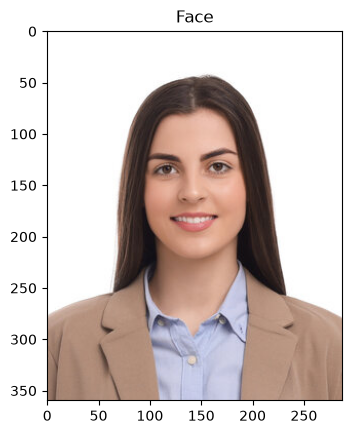

In [2]:
# Load the Face Image
faceImage = cv2.imread('photo.jpg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(360, 288, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(360, 288, 3)

Text(0.5, 1.0, 'glassPNG')

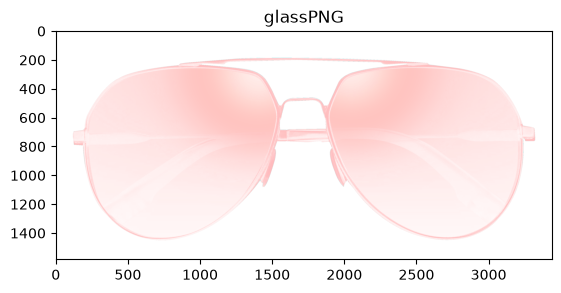

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('glass photo.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [16]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [17]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

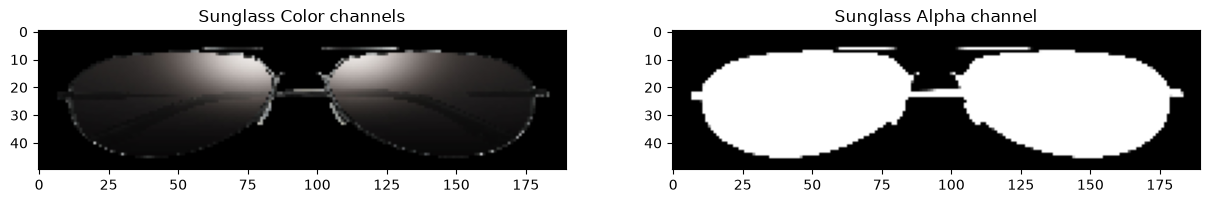

In [18]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

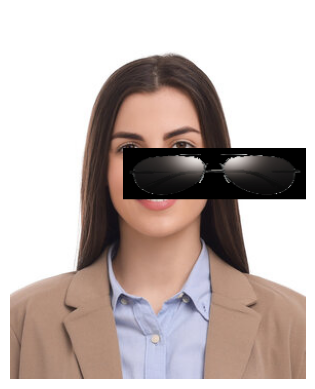

In [20]:
faceWithGlassesNaive = faceImage.copy()

# Target slice-oda exact width & height-ah eduthu glass-ah resize panrom
h, w = faceWithGlassesNaive[135:185, 110:288].shape[:2]
resized_glass = cv2.resize(glassBGR, (w, h))

faceWithGlassesNaive[135:185, 110:288] = resized_glass

plt.imshow(faceWithGlassesNaive[...,::-1])
plt.axis("off")
plt.show()

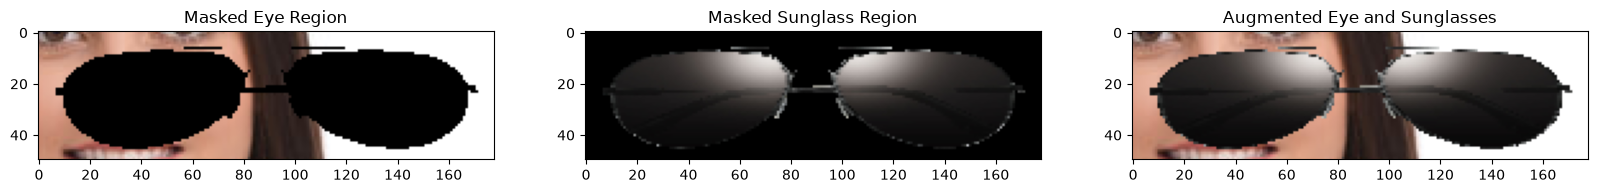

In [22]:
# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1,glassMask1,glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI = faceWithGlassesArithmetic[135:185, 110:288]

# Match mask and glass size to eyeROI shape exactly
h, w = eyeROI.shape[:2]
current_mask = cv2.resize(glassMask, (w, h))
current_glass = cv2.resize(glassBGR, (w, h))

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - current_mask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(current_glass, current_mask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=(20,20))
plt.subplot(131); plt.imshow(maskedEye[...,::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass[...,::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[...,::-1]); plt.title("Augmented Eye and Sunglasses")
plt.show()

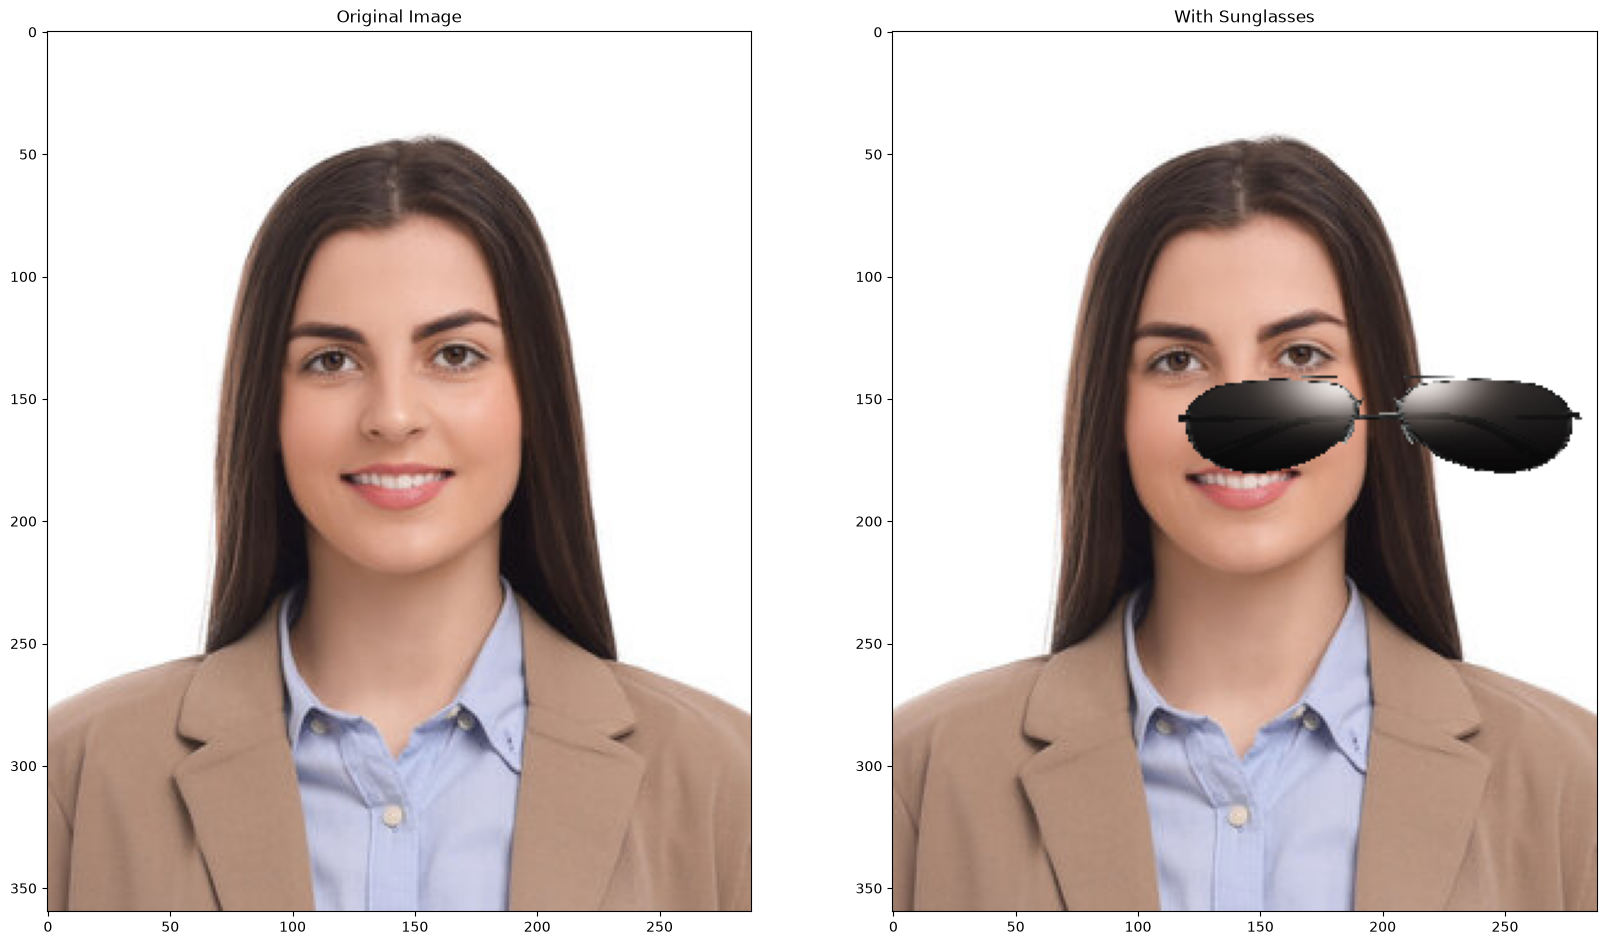

In [23]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[135:185,110:300]=eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20]);
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image");
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses");